# 0-30Y FedWatch Engine — Dashboard

Unified rates curve & probability engine replacing `ffrsdetailed.ipynb`.

| Segment | Horizon | Products | Method |
|---|---|---|---|
| Regime 1 | 0-18M | `ZQ` 30D Fed Funds (+`SR1`) | FOMC day-weighted step probabilities (CME FedWatch parity) |
| Regime 2 | 18M-3Y | `SR3` 3M SOFR futures | Hull-White convexity-adjusted OIS forwards |
| Regime 3 | 3-30Y | Eris SOFR swap futures (`YI*`) | price -> par swap inversion, sequential bootstrap |

Single SOFR-discounting curve via Hagan-West monotone convex forwards.
**Phase 1**: probabilities beyond FOMC horizons are model-based (historical-vol +
Hull-White). **Phase 2** (stubbed): SR3/Treasury options -> SABR -> Breeden-Litzenberger PDFs.

Run all cells top-to-bottom. Set `ASOF = None` for the latest data date.


In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from fedwatch import pipeline as pl
from fedwatch import regime1_fomc as r1
from fedwatch import diagnostics as dg
from fedwatch import densities as dn
from fedwatch import backtest as bt
from fedwatch import plotting as fp

pd.set_option('display.width', 220)
ASOF = None            # e.g. '2026-11-20'; None = latest
REFRESH = False        # True -> pull fresh Databento/FRED/Eris data (~$0.30/day)

In [ ]:
# === MANUAL DATA REFRESH ============================================
# POLICY: no automatic/scheduled pulls. Run THIS cell only when you want
# new data. Cost ~ $0.10 + ~$0.15 x days-since-last-pull.
from fedwatch.refresh import refresh_all
summary = refresh_all(refresh_fomc=True)   # add include_eris_history=True rarely (54MB)


In [2]:
# --- data + curve (one call: SR1 bridge -> SR3 quarters -> Eris long end)
res = pl.run(refresh=REFRESH, asof=ASOF)
asof = res['asof']
print(f"as-of {asof.date()} | {len(res['curve'].dates)} curve nodes -> {res['curve'].dates[-1].date()}")

as-of 2026-11-20 | 24 curve nodes -> 2056-12-20


In [3]:
# --- Regime 1: FOMC meeting probabilities (FedWatch parity)
recs = r1.fomc_probabilities(res['bundle']['fut'], res['bundle']['fred'], res['bundle']['fomc'])
path = r1.expected_path(recs, asof)
print(path.to_string(index=False, float_format=lambda v: f'{v:8.2f}'))

meeting_date  target_after_bps   p_hike    p_cut   p_hold  exp_steps
  2026-12-09            411.25     0.93     0.00     0.07       0.93
  2027-01-27            420.94     0.96     0.00     0.04       0.39
  2027-03-17            434.22     0.98     0.00     0.02       0.53
  2027-04-28            429.94     0.93     0.00     0.07      -0.17
  2027-06-09            435.65     0.94     0.00     0.05       0.23
  2027-07-28            443.77     0.96     0.00     0.04       0.32
  2027-09-15            444.77     0.96     0.00     0.04       0.04
  2027-10-27            440.90     0.93     0.01     0.06      -0.16
  2027-12-08            432.13     0.85     0.03     0.12      -0.35


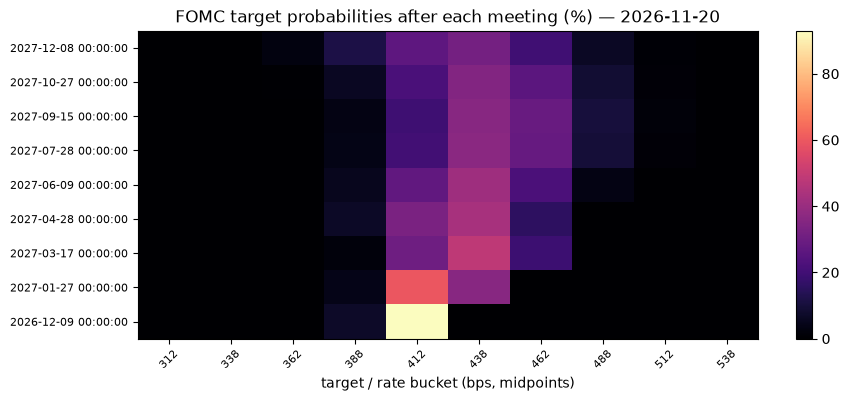

In [4]:
# --- FedWatch-style probability matrix per meeting (%, 25bp buckets)
mat = r1.meeting_matrix(recs, asof)
(fp.plot_probability_heatmap(mat, title=f'FOMC target probabilities after each meeting (%) — {asof.date()}'),)
plt.gcf().set_size_inches(10, 4); plt.colorbar(plt.gca().images[0]); plt.show()

In [5]:
# --- verification suite (must all pass)
print(dg.check_curve(res).to_string(index=False))
print(dg.check_probabilities(recs, asof).to_string(index=False))

                  check  pass                                                                                 detail
     forward positivity  True                                                                    min inst-fwd 3.878%
  front segment present  True                                       6 nodes in first 15M (SR1 bridge + SR3 quarters)
SR3 quarterly repricing  True                                                     max |gap| 0.227bp over 13 quarters
  Eris published parity  True 4Y -0.55bp; 5Y -0.93bp; 7Y -0.42bp; 10Y -0.05bp; 15Y -0.22bp; 20Y -0.61bp; 30Y -2.51bp
   SR3/Eris seam (>=2Y)  True                                                     1Y -5.40bp; 2Y -5.77bp; 3Y -6.62bp
                  check  pass                           detail
FOMC probability sanity  True 9 meetings, max |mass-1| 2.2e-16


In [6]:
# --- cross-product diagnostics: SR3<->Eris seam + published-par parity
print('seam (Eris implied vs SR3-segment curve):')
print(res['seam'].round(2).to_string(index=False))
pc = res['bundle']['eris_parcurve'].asof(asof)
ev = res['eris_eval'].set_index('tenor_years')['par_rate_bps']
print('\nEris tenor parity vs their published par curve (bps):')
for t, col in [(4,'SOFR4Y'),(5,'SOFR5Y'),(7,'SOFR7Y'),(10,'SOFR10Y'),(15,'SOFR15Y'),(20,'SOFR20Y'),(30,'SOFR30Y')]:
    if t in ev.index: print(f'  {t:>2.0f}Y  ours {ev[t]:7.2f}  published {pc[col]*100:7.2f}  diff {ev[t]-pc[col]*100:+5.2f}')

seam (Eris implied vs SR3-segment curve):
 tenor_years  zcode  effective  eris_implied_bps  sr3_curve_bps  gap_bps
         1.0 YIAZ26 2026-12-16            447.91         453.31    -5.40
         2.0 YITZ26 2026-12-16            446.28         452.05    -5.77
         3.0 YICZ26 2026-12-16            442.63         449.25    -6.62

Eris tenor parity vs their published par curve (bps):
   4Y  ours  440.24  published  440.78  diff -0.55
   5Y  ours  439.72  published  440.65  diff -0.93
   7Y  ours  443.16  published  443.57  diff -0.42
  10Y  ours  451.42  published  451.48  diff -0.05
  15Y  ours  464.95  published  465.16  diff -0.22
  20Y  ours  470.39  published  470.99  diff -0.61
  30Y  ours  462.60  published  465.12  diff -2.51


In [7]:
# --- unified master matrix: FOMC meetings + model-based tenor densities
mm = pl.master_matrix(res, recs)
print(f'{mm.shape[0]} buckets x {mm.shape[1]} horizons; col sums:')
print(mm.sum(axis=0).round(4).to_string())

43 buckets x 17 horizons; col sums:
2026-12-09     1.0
2027-01-27     1.0
2027-03-17     1.0
2027-04-28     1.0
2027-06-09     1.0
2027-07-28     1.0
2027-09-15     1.0
2027-10-27     1.0
2027-12-08     1.0
2Y (model)     1.0
3Y (model)     1.0
5Y (model)     1.0
7Y (model)     1.0
10Y (model)    1.0
15Y (model)    1.0
20Y (model)    1.0
30Y (model)    1.0


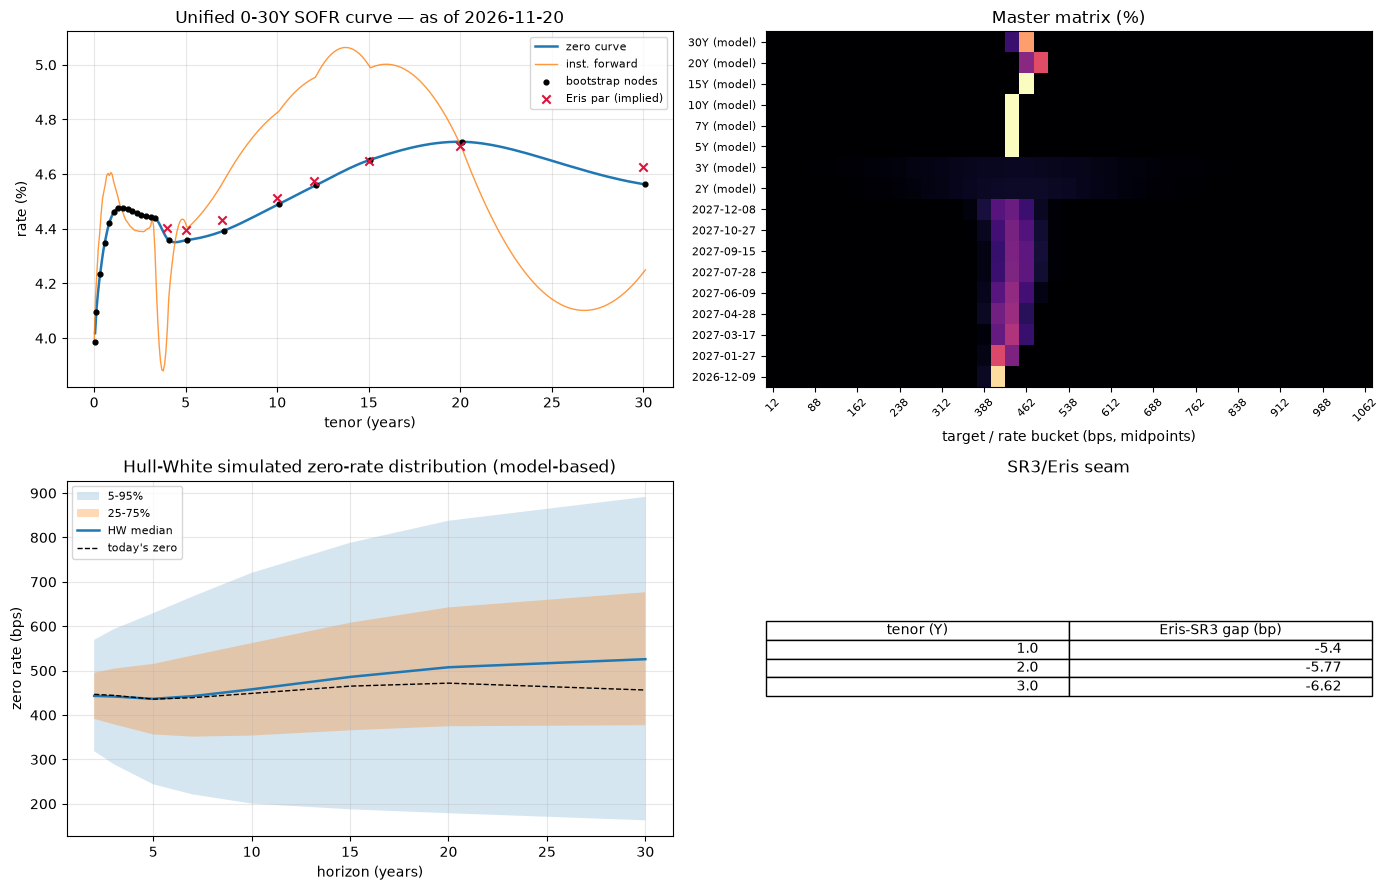

In [8]:
# --- curve + densities dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fp.plot_curve(res, ax=axes[0, 0])
fp.plot_probability_heatmap(mm.T, ax=axes[0, 1], title='Master matrix (%)')
fan = dn.hw_simulate(res['curve'], sigma=0.0095)
fp.plot_hw_fan(fan, res['curve'], asof, ax=axes[1, 0])
axes[1, 1].axis('off')
seam = res['seam']
axes[1, 1].table(cellText=[[r.tenor_years, round(r.gap_bps, 2)] for r in seam.itertuples()],
                 colLabels=['tenor (Y)', 'Eris-SR3 gap (bp)'], loc='center')
axes[1, 1].set_title('SR3/Eris seam')
plt.tight_layout(); plt.show()

In [9]:
# --- historical calibration of the FOMC engine
print(bt.backtest(recs, res['bundle']['fred']).to_string())

            hit_rate  avg_p_realized      n
dtm                                        
(0, 7]         0.778           0.727    576
(7, 14]        0.778           0.731    581
(14, 30]       0.757           0.700   1308
(30, 90]       0.670           0.600   4700
(90, 180]      0.572           0.475   6886
(180, 400]     0.361           0.275  15586


In [10]:
# --- Phase 2: option-implied densities (SR3 options -> SABR -> BL PDFs)
from fedwatch import phase2 as p2
from fedwatch import diagnostics as dg2

opt = p2.load_options()
chains, fits = p2.option_snapshots(res['bundle']['fut'], asof, opt=opt)
print(f"{len(chains)} chains, {len(fits)} SABR fits")
print(fits[['underlying','expiry','horizon_years','atm_vol_bp','rmse_bp','n_quotes']]
      .round(2).to_string(index=False))

13 chains, 11 SABR fits
underlying     expiry  horizon_years  atm_vol_bp  rmse_bp  n_quotes
     SR3Z6 2026-12-16           0.07       38.30    13.66        25
     SR3G7 2027-02-17           0.24       97.80    11.22        12
     SR3H7 2027-03-17           0.32       91.82    29.96        25
     SR3J7 2027-04-21           0.42       60.59    42.03        14
     SR3M7 2027-06-16           0.57       97.88    26.64        29
     SR3U7 2027-09-15           0.82      120.46     8.04        24
     SR3Z7 2027-12-15           1.07      126.41    10.65        29
     SR3H8 2028-03-15           1.32      113.80    16.21        13
     SR3M8 2028-06-21           1.59      117.89    29.74        10
     SR3U8 2028-09-20           1.84      107.74    16.21        13
     SR3Z8 2028-12-20           2.08      130.43     7.20        10


/var/folders/hm/36htpvln1h7d8k8hnh40nt4h0000gn/T/ipykernel_23628/4026483701.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2).to_string(index=False))


In [11]:
# --- option-implied PDFs -> 25bp buckets, merged into the master matrix
opt_cols, opt_check = p2.option_density_columns(fits, res['bundle']['fut'], asof, opt=opt)
print("martingale check (PDF mean vs forward):")
print(opt_check[['underlying','horizon_years','atm_vol_bp','mean_gap_bp']].round(2).to_string(index=False))
mm2 = p2.merge_into_master(mm, opt_cols)
print(f"\nmaster matrix now {mm2.shape[1]} horizons; option columns:",
      [c for c in mm2.columns if '(option)' in c])
print(dg2.check_options(fits, opt_check).to_string(index=False))

martingale check (PDF mean vs forward):
underlying  horizon_years  atm_vol_bp  mean_gap_bp
     SR3Z6           0.07       38.30         0.17
     SR3G7           0.24       97.80         0.39
     SR3H7           0.32       91.82         2.04
     SR3M7           0.57       97.88         5.91
     SR3U7           0.82      120.46         0.50
     SR3Z7           1.07      126.41         5.34
     SR3H8           1.32      113.80         8.85
     SR3U8           1.84      107.74         9.54
     SR3Z8           2.08      130.43         7.35

master matrix now 26 horizons; option columns: ['2026-12-16 (option)', '2027-02-17 (option)', '2027-03-17 (option)', '2027-06-16 (option)', '2027-09-15 (option)', '2027-12-15 (option)', '2028-03-15 (option)', '2028-09-20 (option)', '2028-12-20 (option)']
                   check  pass                               detail
     option fits present  True 11 expiries fit, horizons 0.07-2.08Y
BL martingale |mean-fwd|  True                 worst SR3U8

In [12]:
# --- ATM normal vol term structure -> Regime-2 convexity sigma
from fedwatch.regime2_sr3 import estimate_hw_sigma_from_options
sig_opt = estimate_hw_sigma_from_options(res['bundle']['fut'], asof, opt=opt)
sig_hist = res['sr3_strip'].attrs.get('hw_sigma')
print(f"HW sigma: options-implied {sig_opt*1e4 if sig_opt else float('nan'):.1f}bp "
      f"vs historical proxy {sig_hist*1e4:.1f}bp")
print(p2.atm_vol_term_structure(fits).round(1).to_string())

HW sigma: options-implied 83.4bp vs historical proxy 93.9bp
horizon_years
0.071233     38.3
0.243836     97.8
0.320548     91.8
0.416438     60.6
0.569863     97.9
0.819178    120.5
1.068493    126.4
1.317808    113.8
1.586301    117.9
1.835616    107.7
2.084932    130.4


In [13]:
# --- Phase 3: Treasury futures options -> 5Y/10Y/30Y UST yield densities
from fedwatch import treasury_options as topt
from fedwatch import diagnostics as dg3

ust_cols, ust_check = topt.treasury_density_columns(res, asof)
print("UST option chains:")
print(ust_check[['chain','tenor','n_quotes','atm_vol_pts','atm_vol_yield_bp','y_ref_pct']]
      .round(3).to_string(index=False))
print(dg3.check_treasury(ust_check, asof).to_string(index=False))

UST option chains:


          chain  tenor  n_quotes  atm_vol_pts  atm_vol_yield_bp  y_ref_pct
ZBH7|2027-02-19     30        35       12.192            69.667      5.375
ZFH7|2027-02-19      5        38        4.695           106.704      4.851
ZNH7|2027-02-19     10        31        6.836            78.574      5.039
                  check  pass                                                                    detail
UST option fits present  True 3 chains, tenors [np.int64(5), np.int64(10), np.int64(30)], horizon 0.25Y
    ATM yield vols sane  True                                                    70-107bp across chains
  SABR price-space rmse  True                                            max 0.618pts (7.8% of ATM vol)


In [14]:
# --- merged view: SOFR options (<=2Y) + UST yields (5-30Y) + FOMC + models
mm3 = p2.merge_into_master(mm2, ust_cols)
print(f"master matrix: {mm3.shape[0]} buckets x {mm3.shape[1]} horizons")
print("option-implied columns:", [c for c in mm3.columns if '(option' in c])

master matrix: 43 buckets x 29 horizons
option-implied columns: ['2026-12-16 (option)', '2027-02-17 (option)', '2027-03-17 (option)', '2027-06-16 (option)', '2027-09-15 (option)', '2027-12-15 (option)', '2028-03-15 (option)', '2028-09-20 (option)', '2028-12-20 (option)', '2027-02-19 UST30Y (option)', '2027-02-19 UST5Y (option)', '2027-02-19 UST10Y (option)']


## Phase 3 — Treasury options for the long end (shipped)

OZF/OZN/OZB (5Y/10Y/30Y note & bond futures options, GLBX `OZ*.OPT`) →
OTM-filtered chains → Normal SABR in price space → BL price density →
yield-space mapping via constant dollar duration (v1: ZF 4.4, ZN 8.7, ZB 17.5
pts per 1.00 of yield; CTD tables are the v2 upgrade) → anchored at the
forward Treasury yield (Eris forward par minus standing swap spread) →
25bp buckets labelled `(option, UST…)`.

Notes: these are Treasury-yield distributions (swap-spread-anchored), the
5Y+ analogue of the SOFR option PDFs; American-exercise distortion is
minimised by the OTM-only filter.